## Project Question and Evaluation Plan

### Project Question

Can customer purchasing behaviour be divided into meaningful and stable customer segments using Recency, Frequency, and Monetary (RFM) values? Can unusual customer purchasing patterns also be identified?

### Business Purpose

The purpose of this project is to help a business understand different types of customers, identify valuable customer groups, and find customers with unusual purchasing behaviour.

### Who Will Use the Results?

Marketing teams and business managers can use the results to plan customer retention activities, improve customer engagement, identify high-value customers, and investigate unusual purchasing patterns.

### Evaluation Plan

The clustering results will be evaluated using:

- Silhouette Score to measure cluster separation.
- Agglomerative Clustering comparison using the Adjusted Rand Index (ARI).
- Stability testing across five different random seeds.
- A null-case experiment using independently shuffled feature columns.
- Sensitivity testing by comparing different cluster counts and feature representations.
- Cluster profiling to understand the business meaning of each segment.

Unusual customer detection will be evaluated by comparing Isolation Forest and Local Outlier Factor (LOF), examining their agreement, and reviewing unusual customer patterns across the identified segments.

### Row Independence Assumption

The dataset contains one record for each of the 1,500 unique customer IDs, so there are no repeated rows for the same customer in this file. For this analysis, each row is treated as one customer-level observation. However, unique IDs do not prove statistical independence: customers may respond to shared promotions, seasons, economic conditions, or other common influences. The dataset does not contain group or time information that would allow these shared influences to be tested or controlled. Therefore, the evaluation is customer-row based and may overstate how well the findings generalize to other periods or customer populations.

In [ ]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

#train and test split
from sklearn.model_selection import train_test_split

# Data preprocessing
from sklearn.preprocessing import StandardScaler

# Clustering algorithms
from sklearn.cluster import KMeans, AgglomerativeClustering

# Anomaly detection
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

# Dimensionality reduction
from sklearn.decomposition import PCA

# Evaluation metrics
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score
)

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Visualization settings
sns.set_theme(style="whitegrid")

In [2]:
# Load dataset
df = pd.read_csv("customer_rfm.csv")

# Display first five rows
df.head()

,customer_id,recency_days,frequency,monetary
0,CUST00001,342,4,7861.13
1,CUST00002,644,1,3703.22
2,CUST00003,604,2,4582.42
3,CUST00004,424,1,200.00
4,CUST00005,156,8,25822.11


In [3]:
# Check dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1500
Number of columns: 4


In [4]:
# Display column names
print("Column Names:")
print(df.columns.tolist())

Column Names:
['customer_id', 'recency_days', 'frequency', 'monetary']


In [5]:
# Dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   customer_id   1500 non-null   str    
 1   recency_days  1500 non-null   int64  
 2   frequency     1500 non-null   int64  
 3   monetary      1500 non-null   float64
dtypes: float64(1), int64(2), str(1)
memory usage: 60.2 KB


In [6]:
# Check missing values
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
customer_id     0
recency_days    0
frequency       0
monetary        0
dtype: int64

Total Missing Values: 0


In [7]:
# Check duplicate records
print("Total Duplicate Rows:", df.duplicated().sum())

# Check duplicate customer IDs
print("Duplicate Customer IDs:", df["customer_id"].duplicated().sum())

Total Duplicate Rows: 0
Duplicate Customer IDs: 0


In [8]:
# Statistical summary of numerical columns
df.describe()

,recency_days,frequency,monetary
count,1500.000000,1500.000000,1500.000000
mean,209.247333,7.249333,23671.259973
std,213.456564,5.927781,20727.730281
min,1.000000,1.000000,200.000000
25%,33.750000,3.000000,6090.390000
50%,114.500000,6.000000,19052.630000
75%,329.000000,10.000000,31095.172500
max,729.000000,29.000000,103858.450000


In [9]:
# Check unique customer IDs
print("Total Unique Customers:", df["customer_id"].nunique())

print("Total Customer Records:", len(df))

Total Unique Customers: 1500
Total Customer Records: 1500


In [10]:
# Select RFM features
features = ["recency_days", "frequency", "monetary"]

X = df[features]

# Display selected features
display(X.head())

# Check feature statistics
display(X.describe().round(2))

,recency_days,frequency,monetary
0,342,4,7861.13
1,644,1,3703.22
2,604,2,4582.42
3,424,1,200.00
4,156,8,25822.11


,recency_days,frequency,monetary
count,1500.00,1500.00,1500.00
mean,209.25,7.25,23671.26
std,213.46,5.93,20727.73
min,1.00,1.00,200.00
25%,33.75,3.00,6090.39
50%,114.50,6.00,19052.63
75%,329.00,10.00,31095.17
max,729.00,29.00,103858.45


In [11]:
# Check invalid values
print("Negative Recency Values:", (X["recency_days"] < 0).sum())

print("Zero or Negative Frequency Values:", (X["frequency"] <= 0).sum())

print("Negative Monetary Values:", (X["monetary"] < 0).sum())

Negative Recency Values: 0
Zero or Negative Frequency Values: 0
Negative Monetary Values: 0


Feature Skewness:


,Skewness
recency_days,0.960
frequency,1.182
monetary,1.226


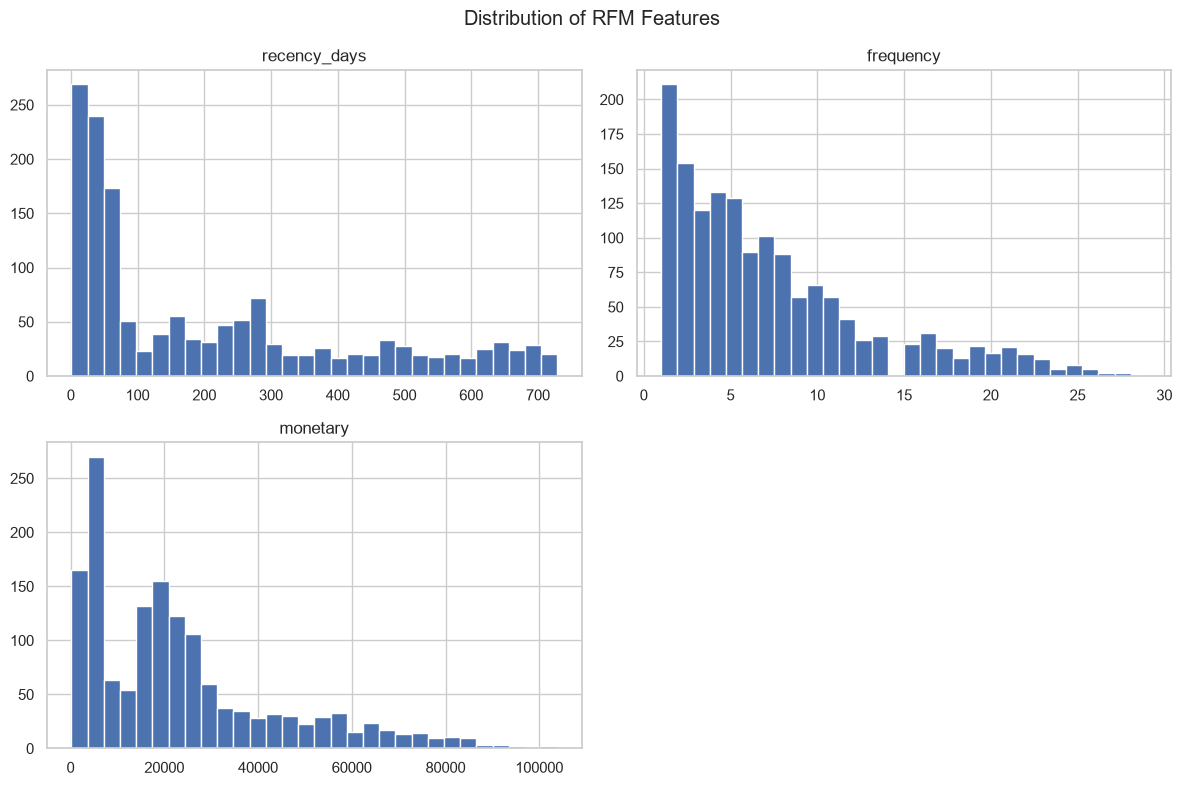

In [12]:
# Select RFM features
features = ["recency_days", "frequency", "monetary"]

X = df[features].copy()

# Check feature skewness
print("Feature Skewness:")
display(X.skew().to_frame(name="Skewness").round(3))

# Plot feature distributions
X.hist(figsize=(12, 8), bins=30)

plt.suptitle("Distribution of RFM Features")
plt.tight_layout()
plt.show()

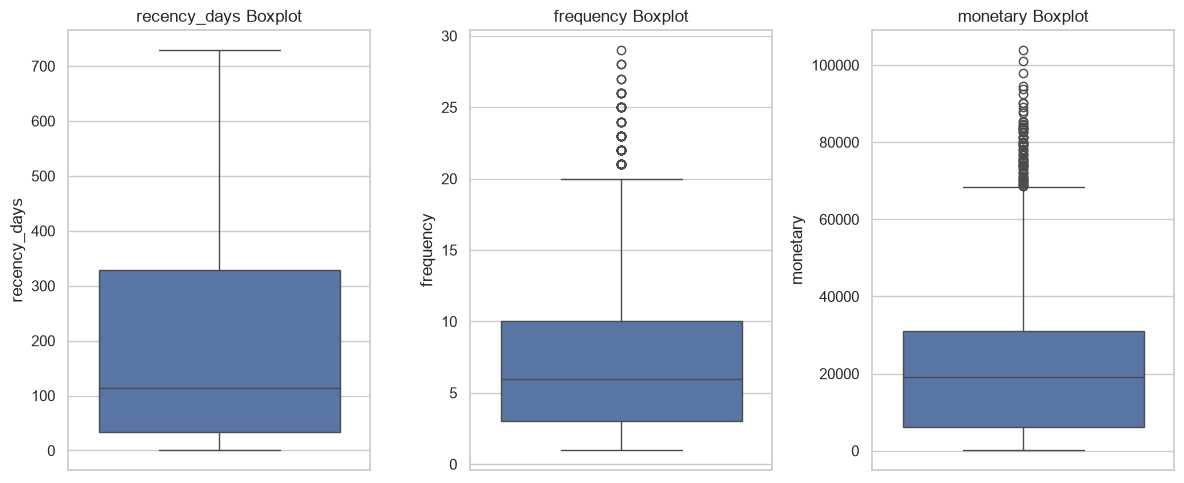

In [13]:
# Visualize possible outliers
plt.figure(figsize=(12, 5))

for i, column in enumerate(features, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=X[column])
    plt.title(f"{column} Boxplot")

plt.tight_layout()
plt.show()

RFM Feature Correlation:


,recency_days,frequency,monetary
recency_days,1.000,-0.616,-0.636
frequency,-0.616,1.000,0.453
monetary,-0.636,0.453,1.000


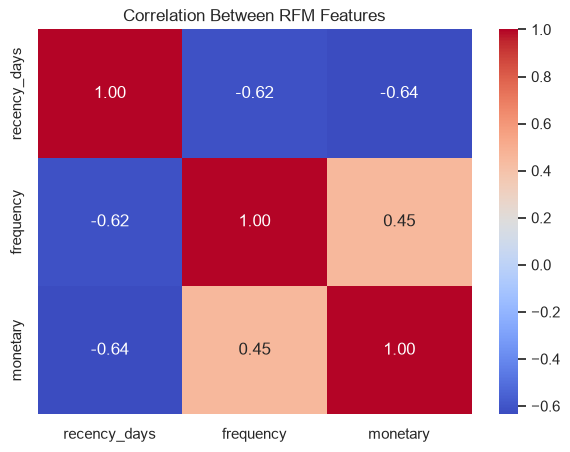

In [14]:
# Calculate correlation between RFM features
correlation_matrix = X.corr()

print("RFM Feature Correlation:")
display(correlation_matrix.round(3))

# Visualize correlation
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between RFM Features")
plt.show()

## Log Transformation

The RFM features show positive skewness, particularly frequency and monetary value.

To reduce the effect of skewness, log1p transformation will be applied to frequency and monetary features. Recency will remain unchanged.

The transformed data will be compared with the original data to understand whether the transformation improves the feature distributions.

In [15]:
# Create a copy of the original RFM features
X_log = X.copy()

# Apply log1p transformation
X_log["frequency"] = np.log1p(X_log["frequency"])
X_log["monetary"] = np.log1p(X_log["monetary"])

# Compare skewness before and after transformation
skewness_comparison = pd.DataFrame({
    "Original Skewness": X.skew(),
    "Transformed Skewness": X_log.skew()
})

display(skewness_comparison.round(3))

,Original Skewness,Transformed Skewness
recency_days,0.960,0.960
frequency,1.182,-0.031
monetary,1.226,-0.675


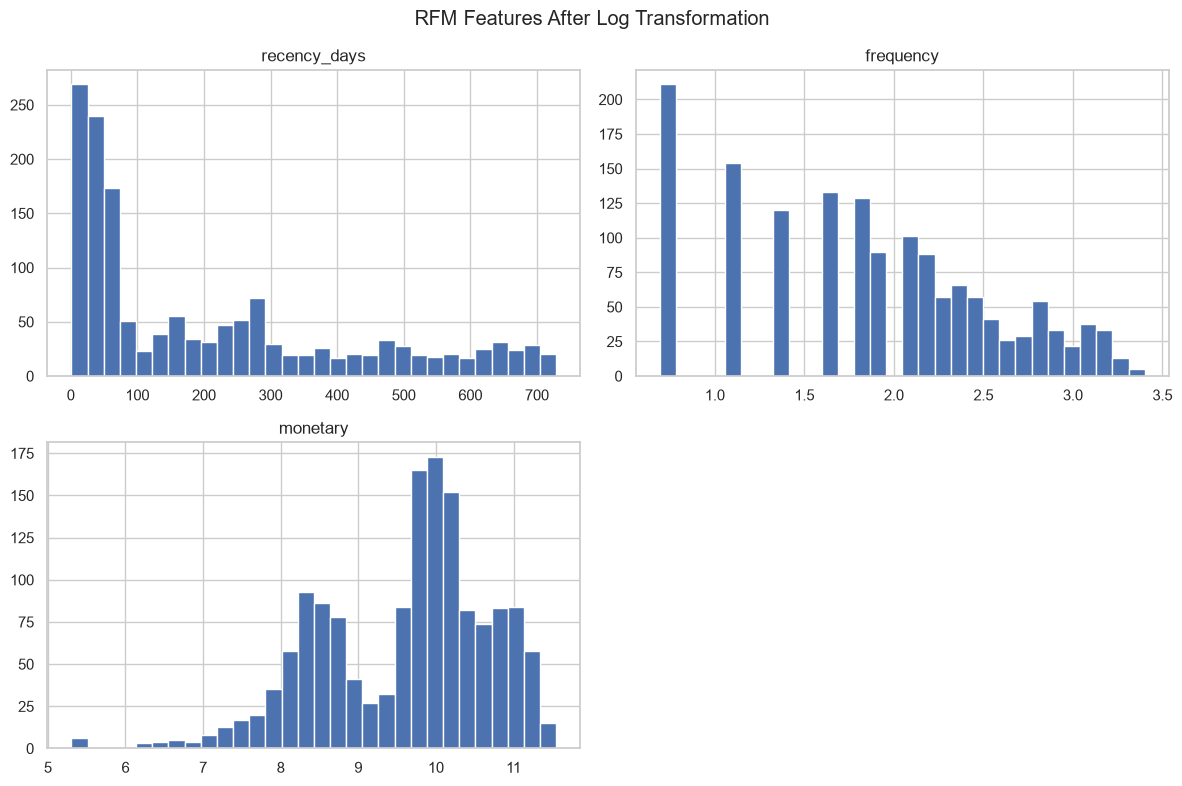

In [16]:
X_log.hist(figsize=(12, 8), bins=30)

plt.suptitle("RFM Features After Log Transformation")
plt.tight_layout()
plt.show()

In [17]:
# Split original RFM features
X_train, X_test, X_log_train, X_log_test = train_test_split(
    X,
    X_log,
    test_size=0.20,
    random_state=42
)

print("Original Training Shape:", X_train.shape)
print("Original Testing Shape:", X_test.shape)

print("Log Training Shape:", X_log_train.shape)
print("Log Testing Shape:", X_log_test.shape)

Original Training Shape: (1200, 3)
Original Testing Shape: (300, 3)
Log Training Shape: (1200, 3)
Log Testing Shape: (300, 3)


In [18]:
# Fit scaler only on training data
scaler_original = StandardScaler()

X_train_scaled = scaler_original.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler_original.transform(X_test)

print("Original Training Scaled Shape:", X_train_scaled.shape)
print("Original Testing Scaled Shape:", X_test_scaled.shape)

Original Training Scaled Shape: (1200, 3)
Original Testing Scaled Shape: (300, 3)


In [19]:
# Fit scaler only on log-transformed training data
scaler_log = StandardScaler()

X_log_train_scaled = scaler_log.fit_transform(X_log_train)

# Transform log-transformed testing data
X_log_test_scaled = scaler_log.transform(X_log_test)

print("Log Training Scaled Shape:", X_log_train_scaled.shape)
print("Log Testing Scaled Shape:", X_log_test_scaled.shape)

Log Training Scaled Shape: (1200, 3)
Log Testing Scaled Shape: (300, 3)


In [20]:
print("Original Training Means:")
print(X_train_scaled.mean(axis=0).round(3))

print("\nOriginal Training Standard Deviations:")
print(X_train_scaled.std(axis=0).round(3))

print("\nLog Training Means:")
print(X_log_train_scaled.mean(axis=0).round(3))

print("\nLog Training Standard Deviations:")
print(X_log_train_scaled.std(axis=0).round(3))

Original Training Means:
[-0.  0. -0.]

Original Training Standard Deviations:
[1. 1. 1.]

Log Training Means:
[-0. -0.  0.]

Log Training Standard Deviations:
[1. 1. 1.]


## Data Quality and Preparation Decisions

### 1. Dataset Overview

The customer RFM dataset contains 1,500 customer records and four columns:

- `customer_id`: Unique customer identification.
- `recency_days`: Number of days since the customer's last purchase.
- `frequency`: Number of purchases made by the customer.
- `monetary`: Total monetary value of customer purchases.

### 2. Data Quality Checks

The following checks were performed:

- Missing values: No missing values were found.
- Duplicate records: No duplicate rows were found.
- Duplicate customer IDs: No duplicate customer IDs were found.
- Invalid values: No negative recency values, non-positive frequency values, or negative monetary values were found.

No missing-value imputation or duplicate removal was required.

### 3. Feature Selection

The three RFM features were selected for customer segmentation:

- Recency
- Frequency
- Monetary

The `customer_id` column was excluded because it is an identifier and does not represent customer purchasing behaviour.

### 4. Skewness and Correlation Analysis

Skewness analysis showed that frequency and monetary values were positively skewed. Recency also showed positive skewness.

Correlation analysis showed:

- Recency and frequency: -0.616
- Recency and monetary: -0.636
- Frequency and monetary: 0.453

These relationships helped understand how customer purchasing behaviour varies across the RFM features.

### 5. Log Transformation

The `log1p()` transformation was tested on frequency and monetary values to reduce positive skewness.

After transformation:

- Frequency skewness changed from 1.182 to -0.031.
- Monetary skewness changed from 1.226 to -0.675.
- Recency was not transformed.

Both original and log-transformed feature representations were retained for comparison during clustering.

### 6. Feature Scaling

StandardScaler was used to standardize the RFM features because clustering algorithms based on distances can be affected by differences in feature scales.

The dataset was divided into training and testing sets using an 80:20 split.

The scaler was fitted only on the training data and then applied to the testing data to avoid data leakage.

### 7. Data Preparation Decisions

The original RFM features and log-transformed features were both evaluated. The original features were retained as an important candidate because they provided useful and interpretable customer segments.

Potential unusual values were not automatically removed because high-value or unusual purchasing behaviour may contain useful business information. Anomaly detection was performed separately.

## Applying Clustering Methods

### K-Means: Selecting the Number of Clusters

K-Means requires the number of clusters to be specified before training.

To identify a suitable number of clusters, the Elbow Method and Silhouette Score will be used.

The Elbow Method examines how the within-cluster sum of squares changes as the number of clusters increases.

The Silhouette Score measures how well-separated the clusters are.

Different values of K, from 2 to 10, will be tested on the training data. Both original and log-transformed features will be examined.

### K-Means assumption

K-Means assigns observations to the nearest cluster centre using distance. It works best when groups are reasonably compact and separated in the scaled feature space. It can be affected by feature scale and extreme values, which is why the RFM features are standardized and unusual observations are reviewed separately.

In [21]:
# Store results for original features
original_results = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_train_scaled)

    inertia = kmeans.inertia_
    silhouette = silhouette_score(X_train_scaled, labels)

    original_results.append({
        "K": k,
        "Inertia": inertia,
        "Silhouette Score": silhouette
    })

original_results_df = pd.DataFrame(original_results)

display(original_results_df.round(4))

,K,Inertia,Silhouette Score
0,2,1779.2167,0.4422
1,3,1125.6938,0.4629
2,4,701.7950,0.5137
3,5,542.3039,0.4374
4,6,459.0707,0.3866
5,7,396.4000,0.3887
6,8,354.9668,0.3748
7,9,319.0984,0.3779
8,10,287.8324,0.3731


In [22]:
# Store results for log-transformed features
log_results = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_log_train_scaled)

    inertia = kmeans.inertia_
    silhouette = silhouette_score(X_log_train_scaled, labels)

    log_results.append({
        "K": k,
        "Inertia": inertia,
        "Silhouette Score": silhouette
    })

log_results_df = pd.DataFrame(log_results)

display(log_results_df.round(4))

,K,Inertia,Silhouette Score
0,2,1266.7896,0.5794
1,3,903.6804,0.4029
2,4,744.0060,0.4174
3,5,618.0597,0.3636
4,6,522.8603,0.3622
5,7,456.6473,0.3696
6,8,417.4827,0.3667
7,9,386.0281,0.3567
8,10,361.3662,0.3243


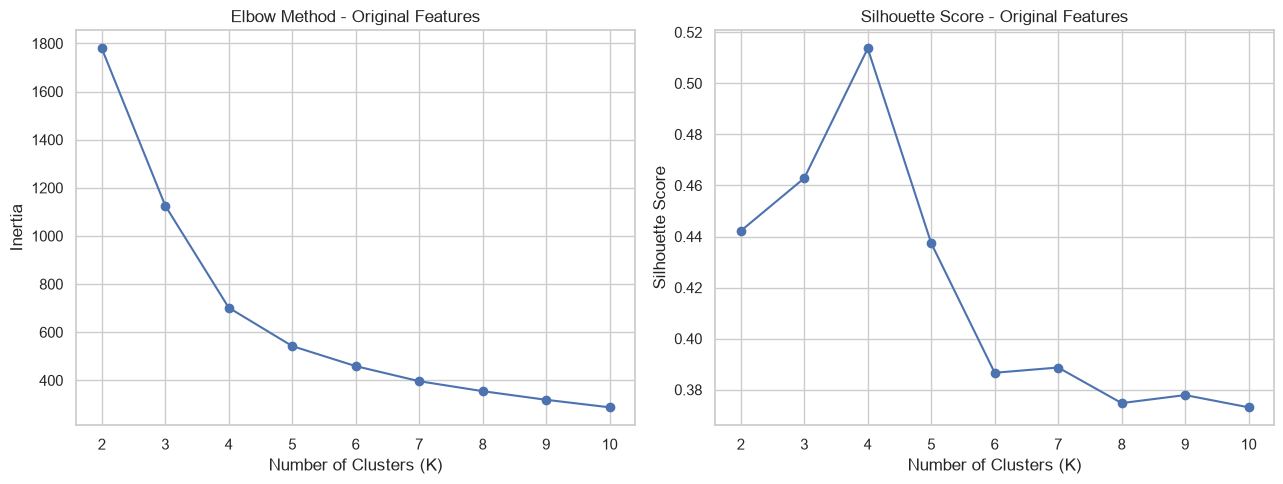

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    original_results_df["K"],
    original_results_df["Inertia"],
    marker="o"
)
axes[0].set_title("Elbow Method - Original Features")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    original_results_df["K"],
    original_results_df["Silhouette Score"],
    marker="o"
)
axes[1].set_title("Silhouette Score - Original Features")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

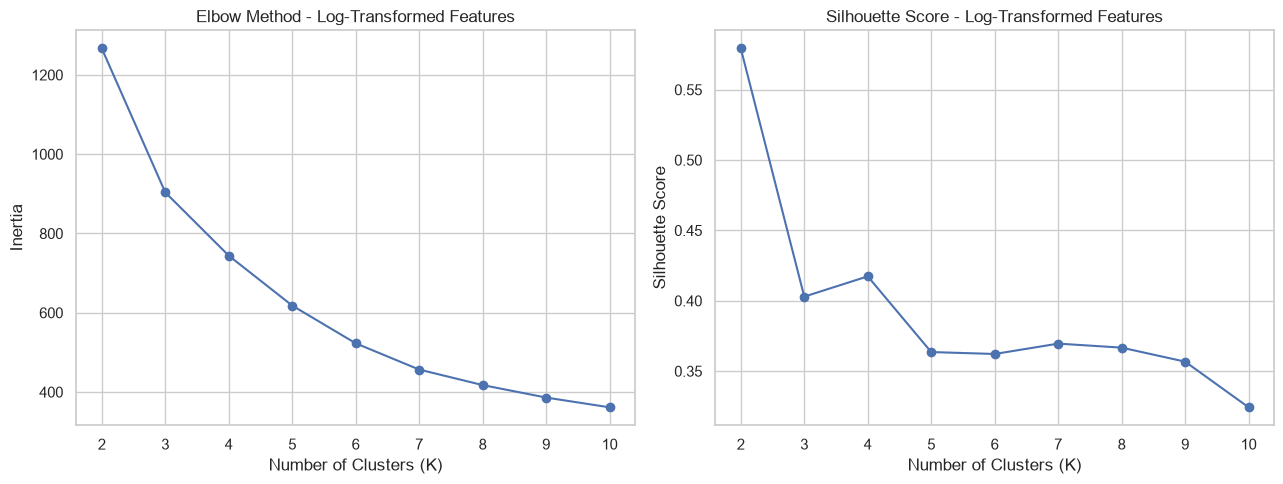

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    log_results_df["K"],
    log_results_df["Inertia"],
    marker="o"
)
axes[0].set_title("Elbow Method - Log-Transformed Features")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    log_results_df["K"],
    log_results_df["Silhouette Score"],
    marker="o"
)
axes[1].set_title("Silhouette Score - Log-Transformed Features")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

## Cluster Profiling

Cluster profiling helps us understand the characteristics of customers assigned to each group.

The original and log-transformed RFM features will be examined using different cluster counts.

For each cluster, the average recency, frequency and monetary values and the number of customers will be calculated.

This analysis will help determine whether the resulting groups have meaningful differences in customer purchasing behaviour.

In [25]:
# Fit K-Means with K=4
kmeans_k4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

labels_k4 = kmeans_k4.fit_predict(X_train_scaled)

# Fit K-Means with K=5
kmeans_k5 = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

labels_k5 = kmeans_k5.fit_predict(X_train_scaled)


# Create original feature profiles
profile_k4 = X_train.copy()
profile_k4["Cluster"] = labels_k4

profile_k5 = X_train.copy()
profile_k5["Cluster"] = labels_k5


print("Original Features - K=4")
display(
    profile_k4.groupby("Cluster")[features]
    .mean()
    .round(2)
)

print("Cluster Sizes - K=4")
display(profile_k4["Cluster"].value_counts().sort_index())


print("\nOriginal Features - K=5")
display(
    profile_k5.groupby("Cluster")[features]
    .mean()
    .round(2)
)

print("Cluster Sizes - K=5")
display(profile_k5["Cluster"].value_counts().sort_index())

Original Features - K=4


,recency_days,frequency,monetary
Cluster,,,
0,67.01,4.03,67248.85
1,492.11,2.14,4311.50
2,112.21,7.51,20551.20
3,20.42,18.44,45937.46


Cluster Sizes - K=4


Cluster
0     96
1    358
2    554
3    192
Name: count, dtype: int64


Original Features - K=5


,recency_days,frequency,monetary
Cluster,,,
0,19.65,18.96,47778.43
1,239.83,4.19,12869.76
2,556.04,2.10,4075.15
3,61.08,9.08,22992.60
4,66.78,4.00,66943.93


Cluster Sizes - K=5


Cluster
0    171
1    284
2    265
3    383
4     97
Name: count, dtype: int64

In [26]:
# Fit K-Means with K=2
kmeans_log_k2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

labels_log_k2 = kmeans_log_k2.fit_predict(X_log_train_scaled)


# Fit K-Means with K=3
kmeans_log_k3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

labels_log_k3 = kmeans_log_k3.fit_predict(X_log_train_scaled)


# Profile using original RFM values for easier business interpretation
log_profile_k2 = X_train.copy()
log_profile_k2["Cluster"] = labels_log_k2

log_profile_k3 = X_train.copy()
log_profile_k3["Cluster"] = labels_log_k3


print("Log-Transformed Features - K=2")
display(
    log_profile_k2.groupby("Cluster")[features]
    .mean()
    .round(2)
)

print("Cluster Sizes - K=2")
display(log_profile_k2["Cluster"].value_counts().sort_index())


print("\nLog-Transformed Features - K=3")
display(
    log_profile_k3.groupby("Cluster")[features]
    .mean()
    .round(2)
)

print("Cluster Sizes - K=3")
display(log_profile_k3["Cluster"].value_counts().sort_index())

Log-Transformed Features - K=2


,recency_days,frequency,monetary
Cluster,,,
0,84.55,9.68,31939.39
1,483.56,2.19,4507.12


Cluster Sizes - K=2


Cluster
0    831
1    369
Name: count, dtype: int64


Log-Transformed Features - K=3


,recency_days,frequency,monetary
Cluster,,,
0,490.19,2.18,4249.99
1,30.97,15.19,37442.08
2,124.49,5.77,27803.27


Cluster Sizes - K=3


Cluster
0    359
1    342
2    499
Name: count, dtype: int64

### Agglomerative Clustering

In this step, Agglomerative Clustering is applied to the standardized original RFM features. Its results are compared with K-Means to understand whether a different clustering approach identifies similar customer groups.

The comparison uses the same training data and evaluates the clustering results using the silhouette score. This helps determine whether the identified customer segments depend heavily on the clustering algorithm.

### Agglomerative Clustering assumption

Agglomerative Clustering starts with individual observations and repeatedly merges the closest groups until the requested number of clusters remains. With the default linkage setting, it uses Ward's approach, which merges groups to limit the increase in within-cluster variation. It can produce a different grouping from K-Means because it builds clusters through successive merges rather than repeatedly assigning customers to centroids.

In [27]:
agg_results = []

for k in [2, 3, 4, 5]:
    agg_model = AgglomerativeClustering(n_clusters=k)

    agg_labels = agg_model.fit_predict(X_train_scaled)

    score = silhouette_score(X_train_scaled, agg_labels)

    agg_results.append({
        "K": k,
        "Silhouette Score": score
    })

agg_results_df = pd.DataFrame(agg_results)

display(agg_results_df.round(4))

,K,Silhouette Score
0,2,0.4543
1,3,0.4524
2,4,0.5079
3,5,0.4437


### Cluster Visualization Using PCA

Principal Component Analysis (PCA) is used to reduce the three standardized RFM features into two principal components. This allows the customer clusters produced by K-Means and Agglomerative Clustering to be visualized in two dimensions.

The visual comparison helps examine cluster separation, overlap, and differences between the two clustering algorithms. PCA is used only for visualization here; the clustering models are fitted using the original three standardized features.

In [28]:
# K-Means with K=4
kmeans_k4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans_labels_k4 = kmeans_k4.fit_predict(X_train_scaled)

# Agglomerative Clustering with K=4
agg_k4 = AgglomerativeClustering(n_clusters=4)

agg_labels_k4 = agg_k4.fit_predict(X_train_scaled)

# Reduce the three features to two principal components
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)

print("Original feature shape:", X_train_scaled.shape)
print("PCA feature shape:", X_train_pca.shape)

print(
    "Explained variance:",
    pca.explained_variance_ratio_.round(4)
)

print(
    "Total explained variance:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

Original feature shape: (1200, 3)
PCA feature shape: (1200, 2)
Explained variance: [0.7219 0.1714]
Total explained variance: 0.8933


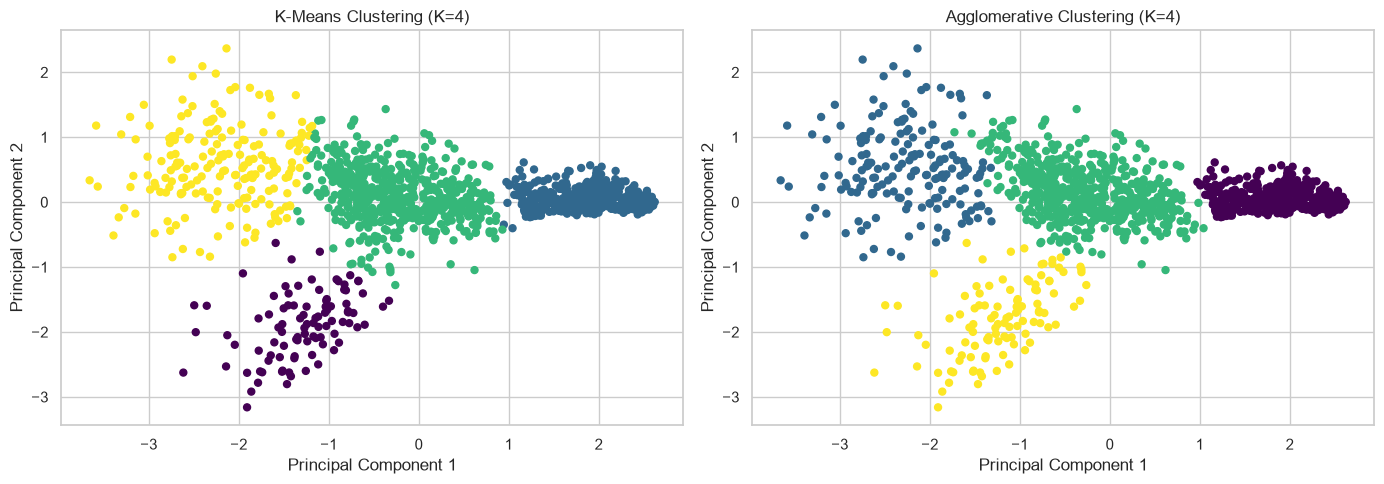

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# K-Means visualization
scatter1 = axes[0].scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=kmeans_labels_k4,
    cmap="viridis",
    s=25
)

axes[0].set_title("K-Means Clustering (K=4)")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

# Agglomerative visualization
scatter2 = axes[1].scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=agg_labels_k4,
    cmap="viridis",
    s=25
)

axes[1].set_title("Agglomerative Clustering (K=4)")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

In [30]:

ari_score = adjusted_rand_score(
    kmeans_labels_k4,
    agg_labels_k4
)

print("K-Means vs Agglomerative ARI:", round(ari_score, 4))

K-Means vs Agglomerative ARI: 0.9251


### Clustering Agreement Analysis

K-Means and Agglomerative Clustering were compared using the Adjusted Rand Index (ARI). The resulting ARI score was 0.9251, indicating very strong agreement between the two clustering methods.

Both algorithms identified highly similar customer groupings when using four clusters and the original standardized RFM features. This provides evidence that the identified customer segmentation is consistent across these two clustering approaches. However, further stability and sensitivity tests are required before considering the segmentation reliable.

### Stability Across Random Seeds

K-Means clustering can produce different results depending on its initial centroid positions. To examine this effect, the model will be fitted using five different random seeds while keeping the dataset, number of clusters, and preprocessing method unchanged.

The Adjusted Rand Index will be used to compare each result with the clustering obtained using the reference seed. This will help evaluate whether the customer segments remain consistent across different initializations.

In [31]:
seeds = [42, 7, 21, 35, 50]

stability_labels = {}

for seed in seeds:
    model = KMeans(
        n_clusters=4,
        random_state=seed,
        n_init=1
    )

    labels = model.fit_predict(X_train_scaled)

    stability_labels[seed] = labels

reference_labels = stability_labels[42]

stability_results = []

for seed in seeds:
    ari = adjusted_rand_score(
        reference_labels,
        stability_labels[seed]
    )

    stability_results.append({
        "Random Seed": seed,
        "ARI vs Seed 42": ari
    })

stability_df = pd.DataFrame(stability_results)

display(stability_df.round(4))

,Random Seed,ARI vs Seed 42
0,42,1.0
1,7,1.0
2,21,1.0
3,35,1.0
4,50,1.0


### K-Means Stability Findings

K-Means clustering with four clusters was tested using five different random seeds: 42, 7, 21, 35, and 50. The Adjusted Rand Index was 1.0000 for every seed when compared with the reference clustering.

This indicates that all five runs produced identical customer group assignments. Therefore, the selected K-Means solution demonstrated strong stability against the tested random initializations. However, this result does not guarantee stability under different datasets, preprocessing choices, or cluster counts.

The stability experiment deliberately uses `n_init=1` so that the effect of the random seed and initial centroid choice is visible. The result is limited to these five seeds and this fixed training sample. It does not establish stability under a different sample, scaling choice, or value of K. The main K=4 model elsewhere uses `n_init=10`, so the stability experiment is a separate diagnostic rather than an exact reproduction of the final model configuration.

### Null Case: Randomized Feature Relationships

A null case is created by independently shuffling the values in each standardized RFM feature. This preserves the individual feature distributions while breaking their original relationships across customers.

K-Means with four clusters is then applied to the randomized data. Its silhouette score is compared with the score from the original training data to examine whether the original customer structure provides stronger clustering separation than randomized feature relationships.

In [32]:
# Original data silhouette score
original_model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

original_labels = original_model.fit_predict(X_train_scaled)

original_silhouette = silhouette_score(
    X_train_scaled,
    original_labels
)

# Create randomized data by independently shuffling each column
rng = np.random.default_rng(42)

X_train_shuffled = X_train_scaled.copy()

for column in range(X_train_shuffled.shape[1]):
    X_train_shuffled[:, column] = rng.permutation(
        X_train_shuffled[:, column]
    )

# K-Means on randomized data
null_model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

null_labels = null_model.fit_predict(X_train_shuffled)

null_silhouette = silhouette_score(
    X_train_shuffled,
    null_labels
)

# Compare results
null_results = pd.DataFrame({
    "Dataset": ["Original Data", "Randomized Data"],
    "Silhouette Score": [
        original_silhouette,
        null_silhouette
    ]
})

display(null_results.round(4))

,Dataset,Silhouette Score
0,Original Data,0.5137
1,Randomized Data,0.3892


### Null Case Findings

A null-case experiment was conducted by independently shuffling the three standardized RFM feature columns while preserving their individual value distributions.

K-Means with four clusters achieved a silhouette score of 0.5137 on the original data and 0.3892 on the randomized data. The original data achieved a higher score by 0.1245.

This indicates that the original customer data contains stronger clustering structure than the independently randomized feature relationships. However, the randomized data also produced some cluster separation, so the result should be interpreted as supporting evidence rather than definitive proof of natural customer segments.

### Sensitivity to the Number of Clusters

The sensitivity of K-Means to the selected number of clusters is examined by comparing K=4 and K=5 on the same original standardized training data.

The silhouette score and cluster sizes are compared to understand how adding one more cluster affects separation and customer distribution. This helps determine whether the additional segment provides useful detail or creates unnecessary complexity.

In [33]:
sensitivity_results = []

for k in [4, 5]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_train_scaled)

    score = silhouette_score(X_train_scaled, labels)

    sizes = pd.Series(labels).value_counts().sort_index()

    sensitivity_results.append({
        "K": k,
        "Silhouette Score": score,
        "Smallest Cluster": sizes.min(),
        "Largest Cluster": sizes.max(),
        "Number of Clusters": len(sizes)
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round(4))

,K,Silhouette Score,Smallest Cluster,Largest Cluster,Number of Clusters
0,4,0.5137,96,554,4
1,5,0.4374,97,383,5


### Sensitivity Analysis Findings

K-Means with four and five clusters was compared using the original standardized RFM features. The K=4 model achieved a silhouette score of 0.5137, while the K=5 model achieved 0.4374.

The smallest cluster sizes were similar, with 96 customers for K=4 and 97 customers for K=5. However, K=4 provided better cluster separation with fewer segments.

Based on these results, K=4 is preferred as the current candidate because it provides a stronger balance between cluster separation and segmentation complexity.

### Unusual Customer Detection Using Isolation Forest

Isolation Forest is applied to the standardized RFM training data to identify customers with unusual purchasing behaviour.

The method assigns an anomaly score and identifies potential unusual observations. These customers will be examined using their original RFM values to understand why their behaviour differs from the general customer population.

The flagged customers are treated as candidates for further investigation, not automatically as incorrect or fraudulent records.

### Isolation Forest assumption

Isolation Forest assumes that unusual observations are easier to separate from the rest of the data through random feature-based splits. It does not know whether a customer is genuinely problematic; it only identifies observations that are relatively easy to isolate in the selected RFM feature space.

### Anomaly Detection Parameter Choices

The contamination value of `0.05` was selected as an exploratory setting so that each method flags approximately 5% of the training customers for review. It is not a known true anomaly rate and must not be interpreted as one. For LOF, `n_neighbors=20` defines the local neighbourhood used to compare customer density. This is a practical starting value, not a value proven to be optimal. The parameter sensitivity check added later compares alternative contamination values and LOF neighbourhood sizes. The number of flagged customers and their overlap with the baseline are reported so that the effect of these choices is visible.

In [34]:
isolation_model = IsolationForest(
    contamination=0.05,
    random_state=42
)

anomaly_labels = isolation_model.fit_predict(X_train_scaled)

print("Normal customers:", (anomaly_labels == 1).sum())
print("Unusual customers:", (anomaly_labels == -1).sum())

Normal customers: 1140
Unusual customers: 60


In [35]:
anomaly_results = X_train.copy()

anomaly_results["customer_id"] = df.loc[X_train.index, "customer_id"]

anomaly_results["Anomaly"] = anomaly_labels

unusual_customers = anomaly_results[
    anomaly_results["Anomaly"] == -1
].copy()

display(
    unusual_customers.sort_values(
        by="monetary",
        ascending=False
    ).head(15)
)

,recency_days,frequency,monetary,customer_id,Anomaly
265,89,8,103858.45,CUST00266,-1
170,84,2,97965.36,CUST00171,-1
1257,99,3,94438.14,CUST01258,-1
761,92,6,93732.64,CUST00762,-1
615,93,10,92524.55,CUST00616,-1
12,85,3,90271.54,CUST00013,-1
895,53,3,85284.11,CUST00896,-1
975,40,3,84795.04,CUST00976,-1
241,17,20,84003.36,CUST00242,-1
165,67,1,83514.20,CUST00166,-1


### Isolation Forest Findings

Isolation Forest was applied to the 1,200 training customers using a contamination setting of 0.05. It identified 60 unusual customers and 1,140 normal customers.

The flagged records included customers with exceptionally high monetary values, as well as customers whose purchase frequency and monetary values showed unusual combinations.

These customers may represent high-value or uncommon purchasing behaviour. They should be investigated further rather than automatically treated as errors. The 5% detection rate was specified as a model setting and does not establish the true proportion of unusual customers.

### Anomaly Detection Using Local Outlier Factor

Local Outlier Factor (LOF) is applied to the same standardized training data to identify customers with unusual local density patterns.

Its results are compared with Isolation Forest to examine whether different anomaly-detection methods identify similar customers. The flagged observations are considered candidates for further investigation, not confirmed errors.

### Local Outlier Factor assumption

LOF compares the local density around a customer with the local density around its neighbours. A customer may be flagged when its local density is substantially lower than that of nearby customers. This makes LOF sensitive to neighbourhood size and local customer patterns, so it may flag different records from Isolation Forest.

In [36]:
lof_model = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05
)

lof_labels = lof_model.fit_predict(X_train_scaled)

print("Normal customers:", (lof_labels == 1).sum())
print("Unusual customers:", (lof_labels == -1).sum())

Normal customers: 1140
Unusual customers: 60


In [37]:
lof_results = X_train.copy()

lof_results["customer_id"] = df.loc[X_train.index, "customer_id"]

lof_results["Anomaly"] = lof_labels

lof_unusual_customers = lof_results[
    lof_results["Anomaly"] == -1
].copy()

display(
    lof_unusual_customers.sort_values(
        by="monetary",
        ascending=False
    ).head(15)
)

,recency_days,frequency,monetary,customer_id,Anomaly
265,89,8,103858.45,CUST00266,-1
170,84,2,97965.36,CUST00171,-1
761,92,6,93732.64,CUST00762,-1
615,93,10,92524.55,CUST00616,-1
241,17,20,84003.36,CUST00242,-1
1159,32,11,83452.28,CUST01160,-1
669,14,10,79927.79,CUST00670,-1
217,25,21,79340.31,CUST00218,-1
1435,18,25,76804.11,CUST01436,-1
229,9,24,75986.12,CUST00230,-1


### Comparison of Isolation Forest and LOF

Isolation Forest and Local Outlier Factor (LOF) were applied to the same standardized training data using a contamination setting of 0.05.

Both methods identified 60 unusual customers. However, their flagged customer lists may differ. Their agreement will be measured by comparing the customer IDs identified by both methods.

This comparison helps identify customers consistently flagged by different anomaly-detection approaches and customers that are unique to one method.

### Why the methods may disagree

Isolation Forest looks for observations that are easy to isolate across the feature space, whereas LOF looks for observations with unusually low density compared with nearby customers. Therefore, a customer can be unusual globally but not locally, or unusual relative to nearby customers without being easy to isolate globally. The low overlap in this analysis is consistent with these different assumptions; it does not establish which flagged list is correct.

In [38]:
# Get customer IDs flagged by each method
isolation_ids = set(
    df.loc[X_train.index[anomaly_labels == -1], "customer_id"]
)

lof_ids = set(
    df.loc[X_train.index[lof_labels == -1], "customer_id"]
)

# Find common and different customers
common_ids = isolation_ids.intersection(lof_ids)

isolation_only = isolation_ids - lof_ids

lof_only = lof_ids - isolation_ids

# Calculate Jaccard similarity
jaccard_score = len(common_ids) / len(
    isolation_ids.union(lof_ids)
)

print("Isolation Forest flagged:", len(isolation_ids))
print("LOF flagged:", len(lof_ids))
print("Flagged by both methods:", len(common_ids))
print("Only Isolation Forest:", len(isolation_only))
print("Only LOF:", len(lof_only))
print("Jaccard Similarity:", round(jaccard_score, 4))

print("\nCommon unusual customers:")
print(sorted(common_ids))

Isolation Forest flagged: 60
LOF flagged: 60
Flagged by both methods: 19
Only Isolation Forest: 41
Only LOF: 41
Jaccard Similarity: 0.1881

Common unusual customers:
['CUST00136', 'CUST00171', 'CUST00218', 'CUST00230', 'CUST00242', 'CUST00266', 'CUST00616', 'CUST00647', 'CUST00670', 'CUST00762', 'CUST00820', 'CUST00885', 'CUST00901', 'CUST01160', 'CUST01381', 'CUST01435', 'CUST01436', 'CUST01442', 'CUST01478']


### Anomaly Detection Comparison Findings

Isolation Forest and Local Outlier Factor (LOF) each identified 60 unusual customers from the 1,200 training records. However, only 19 customers were flagged by both methods. Each method identified 41 additional customers that were not flagged by the other method.

The Jaccard similarity was 0.1881, indicating relatively low overlap between the two sets of flagged customers. This suggests that unusual customer detection is sensitive to the selected algorithm. Customers identified by both methods may deserve higher priority for manual investigation, while customers identified by only one method should not automatically be ignored.

In [39]:
# Create a comparison table
anomaly_comparison = X_train.copy()

anomaly_comparison["customer_id"] = df.loc[
    X_train.index, "customer_id"
]

anomaly_comparison["Isolation_Forest"] = anomaly_labels
anomaly_comparison["LOF"] = lof_labels

# Categorize each customer
anomaly_comparison["Detection_Group"] = np.select(
    [
        (anomaly_labels == -1) & (lof_labels == -1),
        (anomaly_labels == -1) & (lof_labels == 1),
        (anomaly_labels == 1) & (lof_labels == -1)
    ],
    [
        "Flagged by Both",
        "Isolation Forest Only",
        "LOF Only"
    ],
    default="Normal"
)

# Count customers in each group
display(
    anomaly_comparison["Detection_Group"]
    .value_counts()
    .to_frame("Customer Count")
)

# Show customers flagged by both methods
common_customers = anomaly_comparison[
    anomaly_comparison["Detection_Group"] == "Flagged by Both"
]

display(
    common_customers.sort_values(
        by="monetary",
        ascending=False
    )
)

,Customer Count
Detection_Group,
Normal,1099
Isolation Forest Only,41
LOF Only,41
Flagged by Both,19


,recency_days,frequency,monetary,customer_id,Isolation_Forest,LOF,Detection_Group
265,89,8,103858.45,CUST00266,-1,-1,Flagged by Both
170,84,2,97965.36,CUST00171,-1,-1,Flagged by Both
761,92,6,93732.64,CUST00762,-1,-1,Flagged by Both
615,93,10,92524.55,CUST00616,-1,-1,Flagged by Both
241,17,20,84003.36,CUST00242,-1,-1,Flagged by Both
1159,32,11,83452.28,CUST01160,-1,-1,Flagged by Both
669,14,10,79927.79,CUST00670,-1,-1,Flagged by Both
217,25,21,79340.31,CUST00218,-1,-1,Flagged by Both
1435,18,25,76804.11,CUST01436,-1,-1,Flagged by Both
229,9,24,75986.12,CUST00230,-1,-1,Flagged by Both


### Investigation of Unusual Customers

The anomaly comparison identified 19 customers flagged by both Isolation Forest and LOF, 41 flagged only by Isolation Forest, and 41 flagged only by LOF. The remaining 1,099 customers were not flagged by either method.

The common unusual customers generally showed distinctive combinations of recency, purchase frequency, and monetary value. Several had high purchase frequencies or exceptionally high spending.

These findings suggest that different anomaly-detection methods identify different types of unusual purchasing behaviour. Customers flagged by both methods can be prioritized for further investigation, but their behaviour should not automatically be considered incorrect.

In [40]:
detection_group_profile = (
    anomaly_comparison
    .groupby("Detection_Group")[
        ["recency_days", "frequency", "monetary"]
    ]
    .mean()
)

display(detection_group_profile.round(2))

,recency_days,frequency,monetary
Detection_Group,,,
Flagged by Both,32.42,18.84,69690.69
Isolation Forest Only,171.90,7.56,56892.14
LOF Only,115.27,8.12,14385.05
Normal,215.02,7.15,21800.07


### Detection Group Profile Findings

The average RFM profiles showed clear differences between the anomaly-detection groups. Customers flagged by both methods had the highest average purchase frequency (18.84) and monetary value (69,690.69), with a low average recency of 32.42 days.

Customers flagged only by Isolation Forest had a high average monetary value of 56,892.14. Customers flagged only by LOF had a lower average monetary value of 14,385.05 but a lower average recency than the normal group.

These differences indicate that Isolation Forest and LOF identify different unusual purchasing patterns. The flagged customers should be reviewed according to their individual RFM values rather than automatically classified as errors.

In [41]:
# Add K-Means cluster assignments to the anomaly comparison
anomaly_comparison["Cluster"] = kmeans_labels_k4

# Count detection groups within each cluster
cluster_anomaly_counts = pd.crosstab(
    anomaly_comparison["Cluster"],
    anomaly_comparison["Detection_Group"]
)

display(cluster_anomaly_counts)

# Calculate the percentage of each cluster in every detection group
cluster_anomaly_percentage = pd.crosstab(
    anomaly_comparison["Cluster"],
    anomaly_comparison["Detection_Group"],
    normalize="index"
) * 100

display(cluster_anomaly_percentage.round(2))

Detection_Group,Flagged by Both,Isolation Forest Only,LOF Only,Normal
Cluster,,,,
0,6,23,0,67
1,0,8,5,345
2,0,0,32,522
3,13,10,4,165


Detection_Group,Flagged by Both,Isolation Forest Only,LOF Only,Normal
Cluster,,,,
0,6.25,23.96,0.00,69.79
1,0.00,2.23,1.40,96.37
2,0.00,0.00,5.78,94.22
3,6.77,5.21,2.08,85.94


### Subgroup Analysis Findings

The anomaly-detection results were examined across the four K-Means customer segments.

Cluster 0 had the highest concentration of unusual customers, with 29 out of 96 customers flagged (30.21%). Cluster 3 followed with 27 out of 192 customers (14.06%). Cluster 1 had the lowest unusual-customer concentration at 3.63%.

Cluster 2 contained the highest absolute number of LOF-only detections, with 32 customers. However, these represented only 5.78% of that segment.

These findings indicate that unusual purchasing behaviour is not evenly distributed across customer segments. Cluster 0 deserves particular attention for further investigation because it has the highest proportion of flagged customers.

## Held-Out Customer Check

The 300 customers in the test split were not used to fit the scaler or the K-Means clustering model. The fitted training scaler is applied to the test customers, and the fitted K-Means model assigns them to the nearest learned cluster centre. This is a descriptive held-out assignment check, not proof that the segments will remain stable over time. Isolation Forest is also fitted on the training data and used to flag possible unusual customers in the test set. For LOF, `novelty=True` allows the fitted training neighbourhood model to score new observations. These outputs remain unsupervised flags, not confirmed errors.

In [42]:
# Apply the already-fitted training scaler to the held-out customers
X_test_scaled_for_evaluation = scaler_original.transform(X_test)

# Assign test customers using the already-fitted K-Means K=4 model
test_cluster_labels = kmeans_k4.predict(X_test_scaled_for_evaluation)
test_cluster_counts = pd.Series(test_cluster_labels, name="Cluster").value_counts().sort_index()
print("Held-out customers assigned to each cluster:")
display(test_cluster_counts.to_frame("Customer Count"))

# Profile held-out customers using their original RFM values
test_cluster_profile = X_test.copy()
test_cluster_profile["Cluster"] = test_cluster_labels
print("Held-out RFM profile by assigned cluster:")
display(test_cluster_profile.groupby("Cluster")[features].mean().round(2))

# Evaluate separation among the held-out assignments when all required clusters exist
number_of_test_clusters = len(np.unique(test_cluster_labels))
if 2 <= number_of_test_clusters < len(X_test_scaled_for_evaluation):
    test_silhouette = silhouette_score(X_test_scaled_for_evaluation, test_cluster_labels)
    print("Held-out silhouette score:", round(test_silhouette, 4))
else:
    print("Held-out silhouette score was not calculated because the test assignments did not contain a valid number of clusters.")

# Score new customers with Isolation Forest fitted only on training data
isolation_test_model = IsolationForest(contamination=0.05, random_state=42)
isolation_test_model.fit(X_train_scaled)
isolation_test_labels = isolation_test_model.predict(X_test_scaled_for_evaluation)
print("Held-out customers flagged by Isolation Forest:", int((isolation_test_labels == -1).sum()))

# Fit LOF in novelty mode on training data, then score held-out customers
lof_test_model = LocalOutlierFactor(n_neighbors=20, contamination=0.05, novelty=True)
lof_test_model.fit(X_train_scaled)
lof_test_labels = lof_test_model.predict(X_test_scaled_for_evaluation)
print("Held-out customers flagged by LOF:", int((lof_test_labels == -1).sum()))

Held-out customers assigned to each cluster:


,Customer Count
Cluster,
0,35
1,95
2,134
3,36


Held-out RFM profile by assigned cluster:


,recency_days,frequency,monetary
Cluster,,,
0,60.26,4.03,69688.69
1,493.88,2.15,4532.96
2,114.87,7.51,21474.72
3,21.06,18.53,43188.22


Held-out silhouette score: 0.5148
Held-out customers flagged by Isolation Forest: 22
Held-out customers flagged by LOF: 8


### Held-Out Check Interpretation

The held-out customer counts and profiles show how the fitted training segmentation assigns customers that were not used to fit the scaler or K-Means model. The held-out silhouette score, when available, describes separation within this test sample only. The anomaly counts are outputs of models fitted on the training data. No ground-truth labels are available, so these checks cannot establish whether a flagged customer is truly anomalous or whether the segmentation is correct. The split is random and customer-level; shared time or market effects remain an untested limitation.

## Anomaly Parameter Sensitivity

The baseline anomaly models use contamination `0.05`, and LOF uses `n_neighbors=20`. To check whether the flagged-customer results depend strongly on these choices, the following code compares contamination values of 0.03, 0.05, and 0.08. LOF is also compared using 10, 20, and 30 neighbours while contamination is held at 0.05. The comparison reports the number of flagged customers and Jaccard similarity with the baseline flagged set. These values are alternative settings for sensitivity analysis, not claims that any one setting is objectively correct.

In [43]:
# Baseline flagged customer sets from the existing training results
baseline_if = set(np.where(anomaly_labels == -1)[0])
baseline_lof = set(np.where(lof_labels == -1)[0])

def calculate_jaccard(first_set, second_set):
    union = first_set.union(second_set)
    if len(union) == 0:
        return 1.0
    return len(first_set.intersection(second_set)) / len(union)

# Isolation Forest: compare alternative contamination values
if_sensitivity_rows = []
for contamination in [0.03, 0.05, 0.08]:
    model = IsolationForest(contamination=contamination, random_state=42)
    labels = model.fit_predict(X_train_scaled)
    flagged = set(np.where(labels == -1)[0])
    if_sensitivity_rows.append({
        "Contamination": contamination,
        "Flagged Customers": len(flagged),
        "Jaccard vs Baseline": calculate_jaccard(flagged, baseline_if)
    })
print("Isolation Forest contamination sensitivity:")
display(pd.DataFrame(if_sensitivity_rows).round(4))

# LOF: compare alternative neighbourhood sizes and contamination values
lof_sensitivity_rows = []
for neighbors in [10, 20, 30]:
    for contamination in [0.03, 0.05, 0.08]:
        model = LocalOutlierFactor(n_neighbors=neighbors, contamination=contamination)
        labels = model.fit_predict(X_train_scaled)
        flagged = set(np.where(labels == -1)[0])
        lof_sensitivity_rows.append({
            "Neighbors": neighbors,
            "Contamination": contamination,
            "Flagged Customers": len(flagged),
            "Jaccard vs Baseline": calculate_jaccard(flagged, baseline_lof)
        })
print("LOF parameter sensitivity:")
display(pd.DataFrame(lof_sensitivity_rows).round(4))

Isolation Forest contamination sensitivity:


,Contamination,Flagged Customers,Jaccard vs Baseline
0,0.03,36,0.600
1,0.05,60,1.000
2,0.08,96,0.625


LOF parameter sensitivity:


,Neighbors,Contamination,Flagged Customers,Jaccard vs Baseline
0,10,0.03,36,0.3913
1,10,0.05,60,0.5000
2,10,0.08,96,0.4579
3,20,0.03,36,0.6000
4,20,0.05,60,1.0000
5,20,0.08,96,0.6250
6,30,0.03,36,0.6000
7,30,0.05,60,0.7647
8,30,0.08,96,0.6082


### Parameter Sensitivity Interpretation

Compare the flagged-customer counts and Jaccard similarities above. A lower Jaccard value means the flagged list changes more relative to the baseline. If the list changes noticeably across settings, individual anomaly flags should be treated cautiously and reviewed manually. The contamination value controls the expected fraction flagged by the algorithm; it does not measure the real-world prevalence of unusual customers.

## Method Limitations and Systematic Blind Spots

**Systematic blind-spot conclusion:** This RFM-based analysis can fail to detect unusual customer behaviour that is not expressed through recency, purchase frequency, or total monetary value, and it may miss customers whose RFM combinations look locally and globally similar to other customers.

Additional limitations:

- The dataset contains no transaction-level timing, product category, customer demographics, or explanation for a purchase, so the business reason behind a flagged pattern cannot be determined.
- Isolation Forest and LOF use different definitions of unusual behaviour. Their low overlap means a customer not flagged by one method may still be flagged by the other.
- A customer flagged by either method is not necessarily making an incorrect purchase and should not be penalized automatically.
- The analysis contains one row per customer, but shared promotions, seasonality, and market conditions may affect many customers together. The available fields cannot test these dependencies.
- The null experiment shuffles feature columns independently once. It is a useful comparison, but it does not prove that all possible random datasets would produce weaker clusters.
- The stability result covers five seeds on one fixed training sample. It does not guarantee stability on future customer data.

# Business Summary — Customer Segmentation

## Objective

The project examined whether customers could be grouped using Recency, Frequency, and Monetary (RFM) values and whether customers with unusual RFM patterns could be identified.

## Dataset and preparation

The dataset contains 1,500 customer records and four columns. The checks found no missing values, duplicate rows, duplicate customer IDs, or invalid RFM values. The three RFM features were used for analysis; customer ID was excluded because it is an identifier. The data was divided into 1,200 training and 300 testing records. StandardScaler was fitted on the training data only and then applied to the test data.

## Main segmentation finding

K-Means with four clusters on the original standardized RFM features is the leading candidate for interpretation. Its training silhouette score was **0.5137**. Agglomerative Clustering with four clusters achieved **0.5079**, and the ARI between the two methods was **0.9251**, showing strong agreement on this training sample.

The five-seed stability experiment reported an ARI of **1.0000** against the seed-42 reference for all tested seeds. This is encouraging for the tested initializations, but it does not prove stability on a different sample, future period, or preprocessing choice. The experiment used `n_init=1` to expose seed sensitivity, while the main K-Means model used `n_init=10`.

The K=4 silhouette score (**0.5137**) was higher than the K=5 score (**0.4374**) in the tested sensitivity comparison. The two-component PCA visualization retained **89.33%** of the variance and was used to inspect the clustering in two dimensions; clustering itself used all three standardized RFM features.

## Unusual customer finding

On the 1,200 training customers, Isolation Forest and LOF each flagged 60 customers. They agreed on 19 customers, and their Jaccard similarity was **0.1881**. This limited overlap indicates that the detected list depends on the anomaly method. Customers flagged by both methods may be reviewed first, but no flag should be treated as proof of an error or misconduct.

The existing subgroup analysis found the highest share of customers flagged by at least one method in Cluster 0: 29 of 96 customers (**30.21%**). This is a prioritization signal for review, not a verified problem rate.

## Confidence and limitations

The findings have **moderate, preliminary support**: the clustering has reasonable separation on the training data, the two clustering approaches agree strongly, and the tested seeds give consistent assignments. However, the null experiment still produced a silhouette score of **0.3892** after independently shuffling feature columns, so clustering algorithms can produce apparent separation even when original feature relationships are broken. The original score was higher by 0.1245, which is supporting evidence rather than proof of natural segments.

The dataset contains one row per unique customer, but this does not establish statistical independence. Shared promotions, seasonality, or market conditions may affect multiple customers; the available data cannot test these effects. The analysis uses only three RFM features and cannot detect unusual behaviour that is not reflected in those values. Anomaly results also depend on contamination and LOF neighbourhood settings.

## Recommendation

Use the four segments as a **pilot for understanding and planning customer engagement**, not as an automated decision rule. Marketing teams can review the segment profiles when planning retention, repeat-purchase, and reactivation activities. Manually review unusual customers, especially those flagged by both anomaly methods, before taking any action.

## Before deployment

Repeat the analysis on a later customer period and check whether cluster profiles, cluster sizes, and customer assignments remain consistent. Review the parameter-sensitivity tables and investigate flagged customers using transaction-level context. Confirm that the segments remain useful to the business before automating campaigns or customer treatment.


## Submission and Reproducibility Notes

For submission, keep this notebook together with `customer_rfm.csv` and a `README.md` that states the project question, dataset source, main decisions, headline findings, and how to run the notebook. The dataset file was not included with the notebook provided for this correction, so a fresh-kernel execution could not be verified in this environment. Before submission, place `customer_rfm.csv` in the same folder as this notebook, restart the kernel, and run every cell from top to bottom. Confirm that all tables and plots are generated without relying on saved outputs from an earlier run.